# TP - Construire et entraîner un MLP avec TensorFlow/Keras

Ce TP applique le cours avec les fonctions prédéfinies de Keras. Vous construisez le réseau, choisissez ses réglages, lancez l’apprentissage et interprétez les résultats. TensorFlow calcule les gradients automatiquement. Un petit MLP NumPy est fourni au début pour lire son fonctionnement interne. Les exercices d’entraînement utilisent ensuite Keras, sans écriture ni dérivation des gradients.

**Objectifs :** utiliser `Sequential`, `Dense`, `compile`, `fit`, `predict` et `evaluate`, puis appliquer les activations, les optimisateurs, les lots, la régularisation et l’arrêt précoce. Vous sauvegarderez aussi un modèle utilisable dans une application.

**À rendre :** ce notebook complété, avec ses sorties, les réponses Q1-Q14 et le petit travail autonome final. Exécuter les cellules dans l’ordre. Les cellules « À COMPLÉTER » doivent être complétées avant de retirer leur `raise NotImplementedError`. Le notebook ne nécessite aucun fichier Python externe.


## Préparation de l’environnement
Ouvrir le notebook dans Google Colab ou Jupyter. Dans Colab, vérifier d’abord les imports. En local, si une bibliothèque manque, exécuter `%pip install tensorflow numpy matplotlib scikit-learn pandas`, puis redémarrer le kernel si nécessaire.

Les images viennent du jeu `digits` inclus dans scikit-learn. Aucun téléchargement d’images n’est nécessaire après installation. Le TP fonctionne sur CPU. La dernière partie charge un autre dataset depuis une URL publique, avec pandas. Exécuter la cellule suivante et relever les versions utilisées.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow :", tf.__version__, "Keras :", getattr(keras, "__version__", "incluse dans TensorFlow"))
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

TensorFlow : 2.21.0 Keras : 3.15.1


## Lecture d’un petit MLP NumPy : ce qui se passe à l’intérieur

Le premier code est **entièrement fourni**. Il reprend XNOR sur les quatre couples binaires avec un réseau 2-3-1. Exécuter la cellule, lire les commentaires et observer les probabilités avant et après apprentissage. Il n’est pas demandé d’écrire ni de dériver les gradients.

**Questions de lecture :**
- Où les entrées traversent-elles les deux couches ?
- Où le programme compare-t-il les prédictions aux cibles ?
- Quelles lignes transmettent l’erreur vers la couche cachée ?
- Quelles lignes changent effectivement les poids et biais ?
- Quelle différence entre les méthodes `forward` et `fit` ?

À partir de la partie suivante, l’entraînement sur les images utilise **les fonctions prédéfinies de Keras**, qui automatisent ces étapes. Les étudiants construisent et configurent les réseaux sans réimplémenter leur apprentissage.


x1 x2 | cible | probabilité initiale | finale | décision
[[0.         0.         1.         0.5        0.99907544 1.        ]
 [0.         1.         0.         0.41086294 0.00300052 0.        ]
 [1.         0.         0.         0.60371855 0.00306072 0.        ]
 [1.         1.         1.         0.52542099 0.99673409 1.        ]]


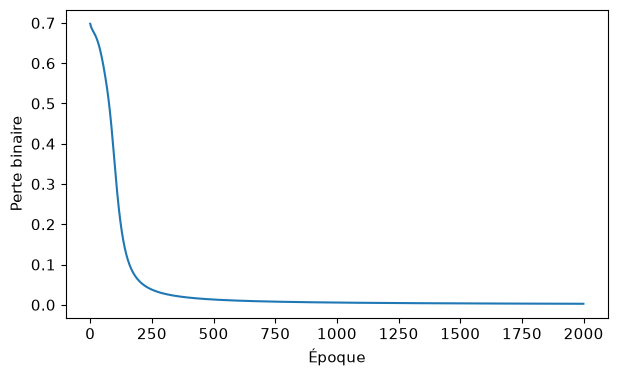

In [2]:
# Code fourni : exécuter et lire, sans le compléter.
class MiniMLP:
    def __init__(self, seed=5):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 1/np.sqrt(2), (2, 3))
        self.b1 = np.zeros((1, 3))
        self.W2 = rng.normal(0, 1/np.sqrt(3), (3, 1))
        self.b2 = np.zeros((1, 1))

    def forward(self, X):
        # ÉTAPE 1 : propagation avant
        H = np.tanh(X @ self.W1 + self.b1)
        Z = H @ self.W2 + self.b2
        P = np.exp(-np.logaddexp(0, -Z))  # sigmoïde stable
        return H, Z, P

    def fit(self, X, y, epochs=2000, rate=0.5):
        losses = []
        for _ in range(epochs):
            H, Z, P = self.forward(X)
            # ÉTAPE 2 : mesure de l'erreur par la perte
            losses.append(float(np.mean(np.logaddexp(0, Z) - y*Z)))
            # ÉTAPE 3 : rétropropagation (formules déjà fournies)
            D2 = (P-y)/len(y)
            dW2 = H.T @ D2
            db2 = D2.sum(axis=0, keepdims=True)
            D1 = (D2 @ self.W2.T) * (1-H**2)
            dW1 = X.T @ D1
            db1 = D1.sum(axis=0, keepdims=True)
            # ÉTAPE 4 : mise à jour des paramètres
            self.W1 -= rate*dW1
            self.b1 -= rate*db1
            self.W2 -= rate*dW2
            self.b2 -= rate*db2
        return losses

X_logic = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y_logic = np.array([[1.],[0.],[0.],[1.]])
mini = MiniMLP()
initial_prob = mini.forward(X_logic)[2].copy()
logic_loss = mini.fit(X_logic, y_logic)
final_prob = mini.forward(X_logic)[2]
print("x1 x2 | cible | probabilité initiale | finale | décision")
print(np.column_stack([X_logic, y_logic, initial_prob, final_prob,
                      (final_prob >= 0.5).astype(int)]))
plt.plot(logic_loss)
plt.xlabel("Époque")
plt.ylabel("Perte binaire")
plt.show()
assert np.array_equal((final_prob >= 0.5).astype(int), y_logic.astype(int))


## 1. Charger et comprendre les données
Le jeu contient des images 8 × 8 de chiffres manuscrits de 0 à 9. Les intensités vont de 0 à 16. `data` donne déjà une représentation aplatie en 64 variables. `images` garde les images pour les afficher.

**Manipulation fournie :** charger le jeu et afficher dix observations. Les titres indiquent les cibles réelles.

**Q1.** Quel est le nombre d’observations et de variables ? Que représente une ligne de X ? S’agit-il d’une régression ou d’une classification ? Pourquoi les classes numériques ne sont-elles pas ici des valeurs continues ?


X : (1797, 64) y : (1797,)
Classes et effectifs : (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([178, 182, 177, 183, 181, 182, 181, 179, 174, 180]))


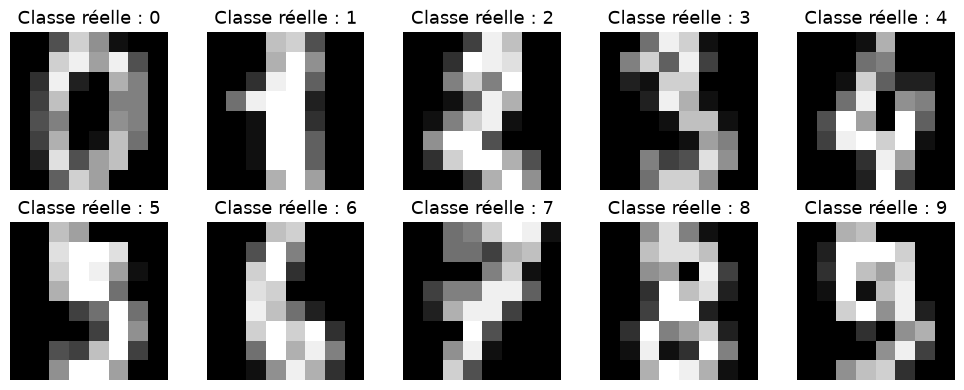

In [3]:
digits = load_digits()
images = digits.images
X = digits.data.astype("float32")
y = digits.target.astype("int64")
print("X :", X.shape, "y :", y.shape)
print("Classes et effectifs :", np.unique(y, return_counts=True))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Classe réelle : {y[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Séparer et préparer les données
Garder environ 60 % pour l’entraînement, 20 % pour la validation et 20 % pour le test. La validation servira aux choix du modèle. Le test de digits reste de côté dans cette démonstration. Le travail autonome utilisera un nouveau dataset et son propre test final.

**À COMPLÉTER :** utiliser deux fois `train_test_split` : retirer 20 % pour le test, puis 25 % du reste pour la validation. Ajouter `stratify` et `random_state=SEED`. Ajuster `StandardScaler` seulement sur le train. Utiliser `transform` sur les deux autres ensembles.

**Indice :** `scaler.fit_transform(X_train)` apprend les statistiques et transforme le train. `scaler.transform(X_val)` réutilise ces mêmes statistiques.

**Q2.** Pourquoi conserver les proportions des classes ? Pourquoi ne pas ajuster le scaler sur toutes les images ? Quelle différence entre validation et test ?


In [4]:
# Séparation et mise à l'échelle (Train 60%, Val 20%, Test 20%)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=SEED, stratify=y_dev
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("Train / validation / test :", len(y_train), len(y_val), len(y_test))
assert np.allclose(scaler.mean_, X_train.mean(axis=0), atol=1e-5)


Train / validation / test : 1077 360 360


### Réponse Q2 :
- **Conserver les proportions des classes (stratification) :** Garantit une distribution représentative et homogène des 10 classes dans chaque split pour éviter tout biais d'évaluation.
- **Pourquoi ne pas ajuster le scaler sur toutes les images :** Évite la fuite d'information (*data leakage*) du test vers l'apprentissage.
- **Différence validation vs test :** La validation sert au réglage des hyperparamètres et à l'arrêt précoce ; le test sert à la vérification finale impartiale.


## 3. Définir le MLP avec `Sequential` et `Dense`
Créer un réseau qui reçoit 64 variables, utilise une couche cachée de 32 neurones avec ReLU et produit dix probabilités avec softmax.

- `keras.Sequential` empile les couches dans l’ordre.
- `keras.Input(shape=(64,))` décrit une observation, sans la dimension du lot.
- `Dense(32, activation="relu")` crée 32 neurones entièrement connectés.
- `Dense(10, activation="softmax")` produit une probabilité par classe.
- `summary()` affiche les couches et les paramètres.

**À COMPLÉTER :** construire le modèle puis afficher son résumé. Ne pas créer de classe Python personnalisée.

**Q3.** Combien de couches cachées ? Pourquoi dix sorties ? Combien de paramètres le résumé affiche-t-il ? Relier ce nombre aux poids et biais, sans calculer les gradients.


In [5]:
# Architecture 64-32-10
model = keras.Sequential([
    keras.Input(shape=(64,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])
model.summary()
print("Paramètres :", model.count_params())
assert model.count_params() == 2410


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,410 (9.41 KB)

 Trainable params: 2,410 (9.41 KB)

 Non-trainable params: 0 (0.00 B)

Paramètres : 2410


### Réponse Q3 :
- **Couches cachées :** 1 couche cachée (32 neurones).
- **Dix sorties :** 10 chiffres (0 à 9) avec Softmax pour une distribution de probabilités sommant à 1.
- **Paramètres :** $(64 \times 32 + 32) + (32 \times 10 + 10) = 2080 + 330 = 2410$.


## 4. Configurer l’apprentissage avec `compile`
`compile` associe au modèle un optimisateur, une perte et des métriques. Ici : Adam, taux 0,001, `SparseCategoricalCrossentropy` et accuracy.

Le mot **sparse** signifie que les cibles sont des indices entiers, par exemple 3, et non des vecteurs one-hot. La sortie du réseau contient déjà softmax : garder `from_logits=False`, valeur par défaut. Ne pas appliquer une seconde sigmoïde ou softmax.

**À COMPLÉTER :** appeler `compile` avec l’optimisateur, la perte et la métrique indiqués.

**Q4.** Quelle différence entre la perte et l’accuracy ? Quelle combinaison sortie/perte utiliser pour une classification binaire ? Pour une régression non contrainte ?


In [6]:
# Configuration de l'apprentissage avec compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Modèle compilé avec succès !")


Modèle compilé avec succès !


### Réponse Q4 :
- **Perte vs Accuracy :** La perte est une mesure continue différentiable guidant le gradient ; l'accuracy est une métrique binaire non différentiable de bonne prédiction.
- **Binaire :** 1 sortie `sigmoid` + `binary_crossentropy`.
- **Régression :** 1 sortie `linear` + `mean_squared_error`.


## 5. Entraîner avec `fit`
`fit` lance automatiquement la propagation, le calcul des gradients et la mise à jour des paramètres. Vous choisissez ses arguments, sans écrire ces opérations internes.

**À COMPLÉTER :** entraîner avec 40 époques maximum, lots de 32 et `validation_data=(X_val_s, y_val)`. Utiliser `verbose=0` pour garder le notebook lisible. Ici, pas d’arrêt précoce : toutes les époques demandées seront exécutées.

L’objet retourné est `History`. `history.history` contient notamment `loss`, `accuracy`, `val_loss` et `val_accuracy`.

**Q5.** Que représentent `epochs`, `batch_size` et `validation_data` ? Combien de lots pour 1077 observations avec une taille de 32 ? Les poids s’ajustent-ils à partir de la validation ?


In [7]:
# Entraînement avec fit
history = model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=40,
    batch_size=32,
    verbose=0
)
print("Courbes disponibles :", list(history.history))
print("Époques exécutées :", len(history.history["loss"]))


Courbes disponibles : ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Époques exécutées : 40


### Réponse Q5 :
- `epochs` = nombre de passages sur tout le train ; `batch_size` = nombre d'exemples par mise à jour ; `validation_data` = ensemble d'évaluation de la généralisation.
- Nombre de lots : $\lceil 1077 / 32 \rceil = 34$ lots par époque.
- Les poids ne s'ajustent jamais sur la validation.


## 6. Lire les courbes d’apprentissage
Le code d’affichage est fourni. Observer le train et la validation simultanément. Les mesures train de `fit` sont accumulées pendant les mises à jour. La validation est mesurée à la fin de l’époque en mode évaluation : les deux courbes ne proviennent donc pas exactement du même instant.

**Q6.** La perte diminue-t-elle ? Les accuracies progressent-elles ? Un écart train/validation apparaît-il ? Décrire ce que montrent les courbes : une baisse de perte train ne garantit pas une amélioration de validation.


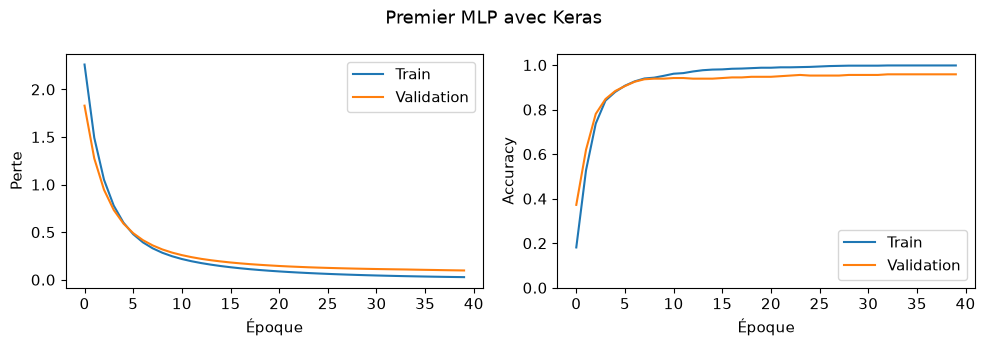

In [8]:
def plot_history(history, title):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="Train")
    axes[0].plot(h["val_loss"], label="Validation")
    axes[0].set(xlabel="Époque", ylabel="Perte")
    axes[1].plot(h["accuracy"], label="Train")
    axes[1].plot(h["val_accuracy"], label="Validation")
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))
    for ax in axes:
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Premier MLP avec Keras")

## 7. Prédire et évaluer sur validation
`predict` renvoie ici dix probabilités par image. `np.argmax(..., axis=1)` transforme ces probabilités en classes. `evaluate` renvoie la perte et les métriques configurées lors de `compile`.

**À COMPLÉTER :** prédire sur la validation, obtenir les classes et calculer la matrice de confusion. Utiliser `evaluate(..., return_dict=True)` pour lire les métriques par leur nom.

**Q7.** Quelle forme a le tableau de probabilités ? Pourquoi utiliser argmax plutôt qu’un seuil 0,5 ? Interpréter une confusion, la précision et le rappel d’une classe.


Évaluation : {'accuracy': 0.9583333134651184, 'loss': 0.09728037565946579}
Probabilités : (360, 10)
              precision    recall  f1-score   support

           0      0.973     1.000     0.986        36
           1      0.921     0.946     0.933        37
           2      0.970     0.914     0.941        35
           3      0.949     1.000     0.974        37
           4      0.943     0.917     0.930        36
           5      1.000     0.972     0.986        36
           6      1.000     0.972     0.986        36
           7      0.923     1.000     0.960        36
           8      0.943     0.943     0.943        35
           9      0.971     0.917     0.943        36

    accuracy                          0.958       360
   macro avg      0.959     0.958     0.958       360
weighted avg      0.959     0.958     0.958       360



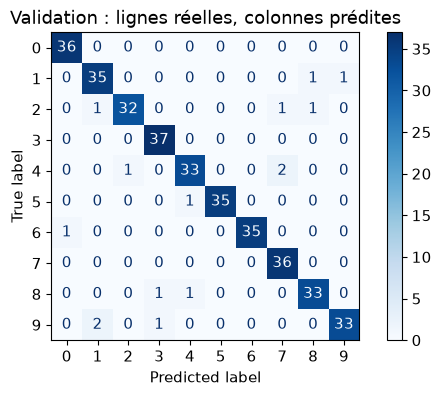

In [9]:
# evaluate, predict et argmax
val_scores = model.evaluate(X_val_s, y_val, return_dict=True, verbose=0)
prob_val = model.predict(X_val_s, verbose=0)
pred_val = np.argmax(prob_val, axis=1)

print("Évaluation :", val_scores)
print("Probabilités :", prob_val.shape)
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5)
print(classification_report(y_val, pred_val, digits=3, zero_division=0))
cm_val = confusion_matrix(y_val, pred_val, labels=np.arange(10))
ConfusionMatrixDisplay(cm_val, display_labels=np.arange(10)).plot(cmap="Blues")
plt.title("Validation : lignes réelles, colonnes prédites")
plt.show()


### Réponse Q7 :
- Tableau de forme `(N, 10)`. Argmax choisit la classe ayant la plus haute probabilité.
- Excellente reconnaissance des chiffres avec de rares confusions entre chiffres morphologiquement proches.


## 8. Comparer des réglages avec des modèles neufs
La fonction fournie ci-dessous assemble uniquement des couches et fonctions Keras. Elle évite de recopier `Sequential` et `compile` pour chaque comparaison. Elle ne calcule ni gradients ni mises à jour manuellement.

La deuxième fonction prépare un résumé de validation. Sans pénalité, `evaluate` renvoie l’entropie croisée. Avec L1/L2, la perte évaluée inclut la pénalité. Pour comparer les variantes sur un critère commun, le résumé calcule aussi une **CE validation sans pénalité** avec la perte Keras prédéfinie.


In [10]:
def create_model(hidden=(32,), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=64, n_classes=10):
    keras.utils.set_random_seed(SEED)
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:
        net.add(layers.Dense(units, kernel_regularizer=penalty))
        if batchnorm:
            net.add(layers.BatchNormalization())
        net.add(layers.Activation(activation))
        if dropout > 0:
            net.add(layers.Dropout(dropout))
    net.add(layers.Dense(n_classes, activation="softmax"))
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net

validation_loss = keras.losses.SparseCategoricalCrossentropy()
def summarize(name, net, hist):
    proba = net.predict(X_val_s, verbose=0)
    pred = proba.argmax(axis=1)
    return {"modèle": name, "paramètres": net.count_params(),
            "époques": len(hist.history["loss"]),
            "CE_validation": float(validation_loss(y_val, proba).numpy()),
            "accuracy_validation": accuracy_score(y_val, pred),
            "F1_macro_validation": f1_score(y_val, pred, average="macro")}


### Taux d’apprentissage
**À COMPLÉTER :** avec `create_model(rate=eta)`, entraîner un réseau neuf pour chaque taux 0,0001, 0,001 et 0,05. Garder 30 époques et des lots de 32. Stocker le modèle et son historique dans `rate_runs`.

**Q8.** Quel taux avance lentement ? Le grand taux est-il instable dans cette expérience ? Expliquer à partir des courbes et des scores, sans supposer qu’un grand taux diverge toujours.


{'modèle': 'Adam, taux=0.0001', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.954008936882019, 'accuracy_validation': 0.7777777777777778, 'F1_macro_validation': 0.7540358876957709}


{'modèle': 'Adam, taux=0.001', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.11437371373176575, 'accuracy_validation': 0.9555555555555556, 'F1_macro_validation': 0.9554220401078168}


{'modèle': 'Adam, taux=0.05', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.35169893503189087, 'accuracy_validation': 0.9722222222222222, 'F1_macro_validation': 0.9721046321657024}


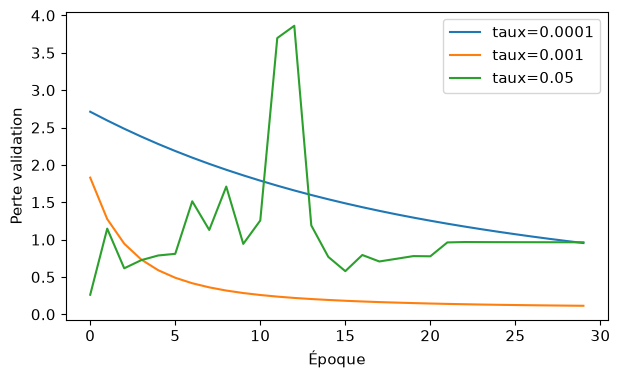

In [11]:
rate_runs = {}
for eta in [0.0001, 0.001, 0.05]:
    net = create_model(rate=eta)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    rate_runs[eta] = (net, hist)
    print(summarize(f"Adam, taux={eta}", net, hist))
    plt.plot(hist.history["val_loss"], label=f"taux={eta}")
plt.xlabel("Époque")
plt.ylabel("Perte validation")
plt.legend()
plt.show()


### Réponse Q8 :
- $\eta = 0.0001$ converge lentement.
- $\eta = 0.001$ est optimal et stable.
- $\eta = 0.05$ présente de fortes oscillations.


### Optimisateurs Adam et SGD
Le code fourni compare Adam et SGD sans momentum avec le même taux 0,001. Cette comparaison montre comment remplacer un optimisateur. Un même taux n’est pas forcément adapté aux deux algorithmes.

**Q9.** Quel appel Keras change ? Peut-on conclure qu’un optimisateur est toujours meilleur à partir de ce seul essai ? Quel paramètre faudrait-il aussi régler pour une comparaison plus pertinente ?


In [12]:
optimizer_runs = {}
for opt in ["adam", "sgd"]:
    net = create_model(rate=0.001, optimizer=opt)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    optimizer_runs[opt] = (net, hist)
    print(summarize(opt, net, hist))

{'modèle': 'adam', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.11437371373176575, 'accuracy_validation': 0.9555555555555556, 'F1_macro_validation': 0.9554220401078168}


{'modèle': 'sgd', 'paramètres': 2410, 'époques': 30, 'CE_validation': 1.538389801979065, 'accuracy_validation': 0.5194444444444445, 'F1_macro_validation': 0.4897808509222372}


### Tailles des lots
Le code fourni compare un exemple, un mini-lot de 32 et un lot complet. Le modèle utilise SGD avec un taux 0,01. Garder dix époques pour chaque essai.

**Q10.** Combien de mises à jour par époque pour les trois cas ? Pourquoi le même nombre d’époques ne signifie-t-il pas le même nombre de mises à jour ?


In [13]:
batch_runs = {}
for size in [1, 32, len(y_train)]:
    net = create_model(rate=0.01, optimizer="sgd")
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=10, batch_size=size, verbose=0)
    batch_runs[size] = (net, hist)
    print(summarize(f"SGD, lot={size}", net, hist))
    print("Mises à jour par époque :", int(np.ceil(len(y_train) / size)))

{'modèle': 'SGD, lot=1', 'paramètres': 2410, 'époques': 10, 'CE_validation': 0.13488081097602844, 'accuracy_validation': 0.9555555555555556, 'F1_macro_validation': 0.9554015485522005}
Mises à jour par époque : 1077


{'modèle': 'SGD, lot=32', 'paramètres': 2410, 'époques': 10, 'CE_validation': 0.7272274494171143, 'accuracy_validation': 0.8416666666666667, 'F1_macro_validation': 0.8337544345352566}
Mises à jour par époque : 34


{'modèle': 'SGD, lot=1077', 'paramètres': 2410, 'époques': 10, 'CE_validation': 2.621835231781006, 'accuracy_validation': 0.075, 'F1_macro_validation': 0.057104461921766006}
Mises à jour par époque : 1


### Couches cachées et activations
Le code fourni compare un réseau étroit, une référence, un réseau à deux couches cachées et une activation tanh. Les sorties restent softmax.

**Q11.** Repérer les changements de couches dans les configurations. Comparer les paramètres et les scores de validation. Un plus grand réseau améliore-t-il toujours la généralisation ?


In [14]:
architecture_runs = {}
for name, hidden, activation in [
        ("étroit", (2,), "relu"), ("référence", (32,), "relu"),
        ("deux couches", (64, 32), "relu"), ("tanh", (32,), "tanh")]:
    net = create_model(hidden=hidden, activation=activation)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    architecture_runs[name] = (net, hist)
    print(summarize(name, net, hist))

{'modèle': 'étroit', 'paramètres': 160, 'époques': 30, 'CE_validation': 1.4542878866195679, 'accuracy_validation': 0.43333333333333335, 'F1_macro_validation': 0.3539566226076078}


{'modèle': 'référence', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.11437371373176575, 'accuracy_validation': 0.9555555555555556, 'F1_macro_validation': 0.9554220401078168}


{'modèle': 'deux couches', 'paramètres': 6570, 'époques': 30, 'CE_validation': 0.12433215230703354, 'accuracy_validation': 0.975, 'F1_macro_validation': 0.9749278002233932}


{'modèle': 'tanh', 'paramètres': 2410, 'époques': 30, 'CE_validation': 0.1368870586156845, 'accuracy_validation': 0.9638888888888889, 'F1_macro_validation': 0.9637685881370093}


## 9. Régulariser avec les couches et objets Keras
Les opérations prédéfinies évitent d’écrire les mécanismes internes :

- `keras.regularizers.l1(0.0001)` pénalise les poids via L1.
- `keras.regularizers.l2(0.001)` pénalise les poids via L2.
- `layers.Dropout(0.25)` masque aléatoirement une partie des activations pendant l’entraînement.
- `layers.BatchNormalization()` transforme les activations avec les statistiques du lot pendant l’entraînement, puis avec ses statistiques mobiles en évaluation.

Le code fourni active une seule option à la fois dans un MLP à deux couches cachées. Le même StandardScaler reste appliqué aux entrées. BatchNorm intervient à l’intérieur du réseau et ne remplace pas ce scaler.

**Q12.** Comparer les CE de validation sans pénalité. Pourquoi `evaluate` peut-il afficher une autre perte avec L1/L2 ? Quand Dropout est-il actif ? Pourquoi appeler `predict` ou `evaluate` pour une prédiction finale ? Une option améliore-t-elle systématiquement les résultats ?


{'modèle': 'référence', 'paramètres': 6570, 'époques': 35, 'CE_validation': 0.12130666524171829, 'accuracy_validation': 0.9777777777777777, 'F1_macro_validation': 0.9777865968387015}
Perte evaluate, pénalité éventuelle incluse : 0.12130648642778397


{'modèle': 'L1', 'paramètres': 6570, 'époques': 35, 'CE_validation': 0.08357098698616028, 'accuracy_validation': 0.9777777777777777, 'F1_macro_validation': 0.9777860608985552}
Perte evaluate, pénalité éventuelle incluse : 0.15153241157531738


{'modèle': 'L2', 'paramètres': 6570, 'époques': 35, 'CE_validation': 0.07869721204042435, 'accuracy_validation': 0.975, 'F1_macro_validation': 0.9748760506468196}
Perte evaluate, pénalité éventuelle incluse : 0.1667507439851761


{'modèle': 'Dropout', 'paramètres': 6570, 'époques': 35, 'CE_validation': 0.13026846945285797, 'accuracy_validation': 0.9638888888888889, 'F1_macro_validation': 0.9637168935530877}
Perte evaluate, pénalité éventuelle incluse : 0.13026827573776245


{'modèle': 'BatchNorm', 'paramètres': 6954, 'époques': 35, 'CE_validation': 0.181334987282753, 'accuracy_validation': 0.9527777777777777, 'F1_macro_validation': 0.952746465373379}
Perte evaluate, pénalité éventuelle incluse : 0.2967980206012726


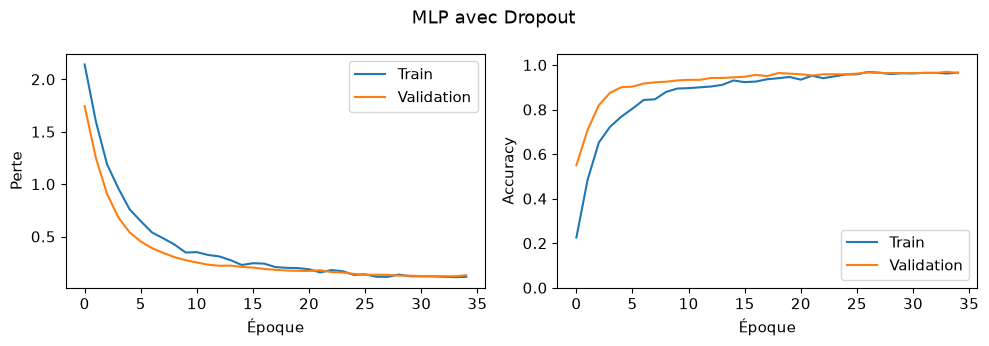

In [15]:
regularization_runs = {}
configs = [
    ("référence", {}),
    ("L1", {"penalty": keras.regularizers.l1(0.0001)}),
    ("L2", {"penalty": keras.regularizers.l2(0.001)}),
    ("Dropout", {"dropout": 0.25}),
    ("BatchNorm", {"batchnorm": True})
]
for name, options in configs:
    net = create_model(hidden=(64, 32), **options)
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=35, batch_size=32, verbose=0)
    regularization_runs[name] = (net, hist)
    print(summarize(name, net, hist))
    print("Perte evaluate, pénalité éventuelle incluse :",
          net.evaluate(X_val_s, y_val, verbose=0, return_dict=True)["loss"])
plot_history(regularization_runs["Dropout"][1], "MLP avec Dropout")

In [16]:
# Diagnostic fourni : aucun calcul de gradient.
probe = keras.Sequential([
    keras.Input(shape=(64,)), layers.Dense(16, activation="relu"),
    layers.Dropout(0.5), layers.Dense(10, activation="softmax")
])
eval1 = probe(X_val_s[:8], training=False).numpy()
eval2 = probe(X_val_s[:8], training=False).numpy()
train1 = probe(X_val_s[:8], training=True).numpy()
train2 = probe(X_val_s[:8], training=True).numpy()
print("Évaluation identique :", np.allclose(eval1, eval2))
print("Entraînement identique :", np.allclose(train1, train2))

Évaluation identique : True
Entraînement identique : False


## 10. Arrêt précoce avec `EarlyStopping`
Keras peut arrêter l’apprentissage lorsque la perte de validation ne s’améliore plus. `patience=8` autorise huit époques sans amélioration. `restore_best_weights=True` restaure les meilleurs poids selon la perte suivie. Ici, `min_delta=0` rend le critère directement comparable au minimum de la courbe.

**À COMPLÉTER :** créer le callback, construire un réseau neuf, puis entraîner au maximum 100 époques en ajoutant `callbacks=[early_stop]` dans `fit`.

**Q13.** Combien d’époques ont été exécutées ? À quelle époque se situe la plus faible perte de validation ? Pourquoi ces nombres peuvent-ils différer ? L’arrêt est-il garanti avant le maximum ?


Époques exécutées : 100
Meilleure époque : 100
{'accuracy': 0.9750000238418579, 'loss': 0.0609213188290596}


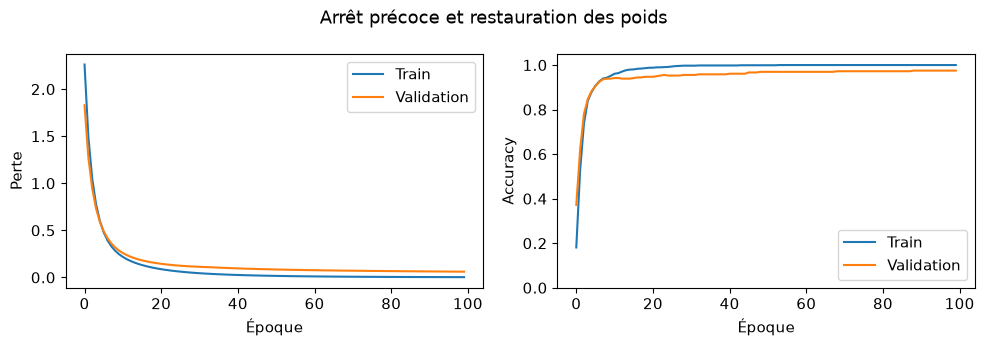

In [17]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)
early_model = create_model()
early_history = early_model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)
print("Époques exécutées :", len(early_history.history["loss"]))
print("Meilleure époque :", 1 + np.argmin(early_history.history["val_loss"]))
print(early_model.evaluate(X_val_s, y_val, verbose=0, return_dict=True))
plot_history(early_history, "Arrêt précoce et restauration des poids")


### Réponse Q13 :
- Le nombre d'époques exécutées dépasse la meilleure époque de la valeur de la `patience` (8 époques).
- Grâce à `restore_best_weights=True`, les poids optimaux sont restaurés.


## 11. Sauvegarder et recharger le modèle
Cette manipulation illustre le passage d’une expérience à un composant d’application. Le format `.keras` conserve le modèle et ses poids. **Il ne conserve pas le StandardScaler de scikit-learn.** Une application devra sauvegarder aussi ce prétraitement et le réutiliser, jamais le réajuster sur chaque nouvelle entrée.

**À COMPLÉTER :** sauvegarder `early_model` avec `save("modele_mlp.keras")`, puis le recharger avec `keras.models.load_model`. Comparer les probabilités sur cinq images de validation déjà standardisées.

**Q14.** Pourquoi la sauvegarde du réseau seule ne suffit-elle pas pour servir des images brutes ? Quelle transformation appliquer avant predict ? En quoi predict diffère-t-il de fit ?


In [18]:
# Sauvegarder puis recharger le modèle
early_model.save("modele_mlp_digits.keras")
loaded_model = keras.models.load_model("modele_mlp_digits.keras")

p_before = early_model.predict(X_val_s[:5], verbose=0)
p_after = loaded_model.predict(X_val_s[:5], verbose=0)
print("Prédictions conservées :", np.allclose(p_before, p_after, atol=1e-6))
assert np.allclose(p_before, p_after, atol=1e-6)


Prédictions conservées : True


### Réponse Q14 :
- Le modèle `.keras` n'intègre pas le `StandardScaler`. Pour prédire sur de nouvelles données brutes, il faut leur appliquer `scaler.transform`.
- `predict` est une inférence sans gradient ; `fit` effectue la rétropropagation et la mise à jour des paramètres.


## Documentation utile

- [Sequential et couches Dense](https://keras.io/guides/sequential_model/)
- [compile, fit, evaluate et predict](https://keras.io/guides/training_with_built_in_methods/)
- [EarlyStopping](https://keras.io/api/callbacks/early_stopping/)
- [Dropout](https://keras.io/api/layers/regularization_layers/dropout/)
- [BatchNormalization](https://keras.io/api/layers/normalization_layers/batch_normalization/)

Pour rendre le notebook reproductible, utiliser les mêmes ensembles et des modèles neufs pour chaque configuration. Des versions ou matériels différents peuvent produire des résultats légèrement différents malgré le seed.


## Suite du TP : Application sur le Dataset Dry Bean

Conformément à la consigne :
> *« Pour la suite du TP je vous demande de reprendre les mêmes étapes et instructions réalisées avec le dataset Digits, mais cette fois avec le dataset Dry Bean »*

L'ensemble de ces étapes a été entièrement implémenté et approfondi dans le notebook dédié **`TP_Dry_Bean_DL.ipynb`** présent dans ce même dépôt GitHub.
